In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import numpy.linalg as linalg
import seaborn as sns



def read_data():
    df = pd.read_csv(r"..\lorenz_data.csv")

    t = df["t"].to_numpy()

    x = df["x"].to_numpy()
    y = df["y"].to_numpy()
    z = df["z"].to_numpy()
    x = [x,y,z]

    xdot = df["x_dot"].to_numpy()
    ydot = df["y_dot"].to_numpy()
    zdot = df["z_dot"].to_numpy()
    xdot = np.array([xdot,ydot,zdot]).T
    return t, x, xdot

def show_lorenztime(t,x,xdot):

    """
    Plots time series data for each component of the statevector
    """


    fig,ax = plt.subplots(3,1)

    for _ in range(3):
        ax[_].plot(t,x[_])
        ax[_].plot(t,xdot[_],"yo",markersize = 0.1)
    plt.show()

def show_lorenzstate(x):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")

    ax.plot(x[0], x[1], x[2])

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    plt.show()

def lorenz(x,b):

    dx = b[0]*(x[1]-x[0])
    dy = x[0]*(b[1]-x[2]) - x[1]
    dz = x[0] * x[1] - b[2]*x[2]
    return [dx,dy,dz]


In [301]:

def build_library(x):

    """
    build a function library based on statevector timeseries
    """

    
    n = len(x)
    variable = ['x', 'y','z']
    names = ["1"]
    Theta = [np.ones_like(x[0])]

    for i in range(n):
        Theta.append(x[i])
        names.append(variable[i])

    for i in range(n):
        for j in range(i, n):
            Theta.append(x[i] * x[j])
            if i == j:
                names.append(f"{variable[i]}^2")
            else:
                names.append(variable[i] + variable[j])


    Theta = np.column_stack(Theta)
    print("Generated Names:", names)

    return np.array(Theta), np.array(names)

def lsq_regression(Theta, xdot):
    reg = []
    for _ in range(3):
        regressiondata,_,_,_ = linalg.lstsq(Theta, xdot[:,_],rcond=None)
        reg.append(regressiondata)

    x = np.column_stack(reg)
    
    return x

In [302]:

def coeff_thresholding(lstsq_sols,threshhold):
    xdatanew = lstsq_sols.copy()
    n = len(lstsq_sols)
    for _ in range(n):
    # using a mask : set those entries of xdata[_] less than the threshhold to zero
        xdatanew[_][np.abs(lstsq_sols[_])<threshhold] = 0
    return xdatanew

# reference = xdata.copy()

def thresholds(Theta, xdot, thresholdata):

    model_selections = []
    xnewdot = xdot.copy()
    for l in thresholdata:
        for m in range(10):
            xdata = lsq_regression(Theta,xnewdot)
            xdata[np.abs(xdata)<l] = 0
            xnewdot = Theta@xdata
        model_selections.append(xdata)
    return np.array(model_selections)


loading the data, dictionary, 

first regression result, a SLTSQ run, 

and resulting sparsity matrix for various threshold values

In [303]:
t,x,xdot = read_data()
xdot.shape

(10001, 3)

In [304]:
Theta, names = build_library(x)
Theta.shape

Generated Names: ['1', 'x', 'y', 'z', 'x^2', 'xy', 'xz', 'y^2', 'yz', 'z^2']


(10001, 10)

In [327]:

thresholdata = np.array([10**(-i) for i in range(25)])
thresholdexp = -np.log10(thresholdata)
model_selections = thresholds(Theta,xdot,thresholdata)
model_selections.shape

(25, 10, 3)

Processing the data, idea: map a sparsity measurement of model for each state-component against threshold exponents

In [306]:
cmpts_models = [] # contains the model-selection for each threshold, for each state-component


for k in range(3):
    cmpt_prog = [] # this contains evolution data for the model-selection-coefficients of component x[k] along the threshold parameter
    for i in range(len(thresholdata)):
        model = selections[i]
        cmpt_prog.append(model[:,k])
    cmpts_models.append(cmpt_prog)

cmpts_models=np.array(cmpts_models)
cmpts_models.shape

(3, 25, 7)

Text(0, 0.5, 'Nonzero elements')

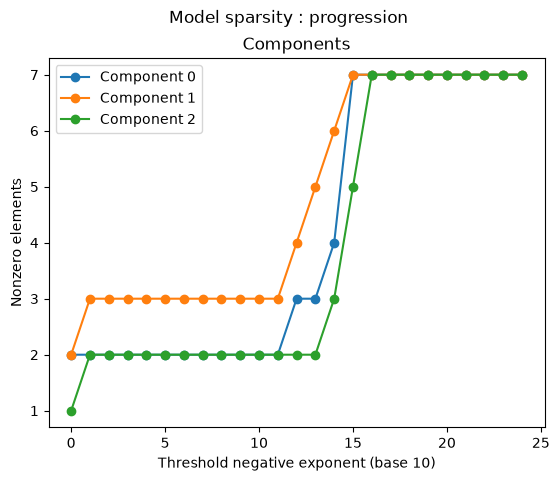

In [307]:
# count the amount of non_zero elements for each model and for each state-component
cmpt_counts = []
for cmpt_models in models_cmpts:
    counts = []
    for model in cmpt_models:
        counts.append(np.count_nonzero(model))
    cmpt_counts.append(counts)

# plotting evolution of sparsity of the model for each state-component
fig, ax = plt.subplots(1,1)
variables = ['x','y','z']  
for i in range(3):
    ax.plot(thresholdexp, cmpt_counts[i],"o-",label=f"Component {i}")
    ax.set_title(f"Components")


fig.suptitle("Model sparsity : progression")
ax.legend()
ax.set_xlabel("Threshold negative exponent (base 10)")
ax.set_ylabel("Nonzero elements")
# the higher the counts, the more terms are selection

Idea : count the zeros in each matrix for each threshold -> iterate over model_selections[i] (has shape 7,3) 

Text(0.5, 1.0, 'Model selection : sparsity for each threshold')

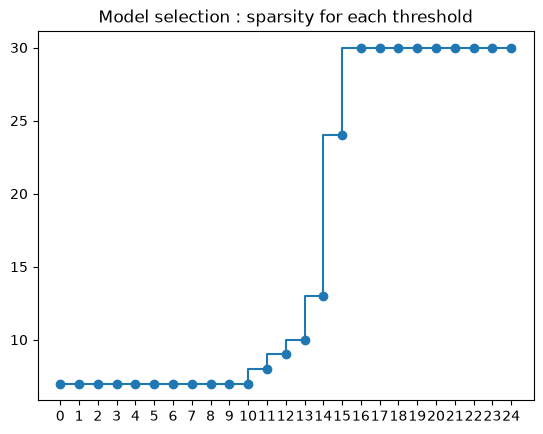

In [308]:
counts = []
for selection in model_selections:
    counts.append(np.count_nonzero(selection))
    
plt.step(thresholdexp,counts,"o-")
plt.xticks(np.arange(min(thresholdexp), max(thresholdexp) + 1, 1))
plt.title("Model selection : sparsity for each threshold")

Analyze the equations that are recovered from the data, for each threshold in thresholdata

In [318]:
names

array(['1', 'x', 'y', 'z', 'x^2', 'xy', 'xz', 'y^2', 'yz', 'z^2'],
      dtype='<U3')

In [332]:
model_selections.shape

(25, 10, 3)

In [ ]:
for i in range(len(model_selections)):
    print(f"Model: {i} |" + f" Threshold exponent: {-thresholdexp[i]}" )
    for j in range(3):
        print(names[model_selections[i][:,j]!=0])

Model: 0 | Threshold exponent: 0.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 1 | Threshold exponent: -1.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 2 | Threshold exponent: -2.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 3 | Threshold exponent: -3.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 4 | Threshold exponent: -4.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 5 | Threshold exponent: -5.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 6 | Threshold exponent: -6.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 7 | Threshold exponent: -7.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 8 | Threshold exponent: -8.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 9 | Threshold exponent: -9.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 10 | Threshold exponent: -10.0
['x' 'y']
['x' 'y' 'xz']
['z' 'xy']
Model: 11 | Threshold exponent: -11.0
['x' 'y']
['1' 'x' 'y' 'xz']
['z' 'xy']
Model: 12 | Threshold exponent: -12.0
['1' 'x' 'y']
['1' 'x' 'y' 'xz']
['z' 'xy']
Model: 13 | Threshold exponent: -13.0
['1' 'x' 

In [337]:
model_selections[0][:,0]

array([  0., -10.,  10.,   0.,   0.,   0.,   0.,   0.,   0.,   0.])